In [1]:
import json
import random
import base64
import os
import shutil
import subprocess
import dill
import nltk
import itertools
import io
import math
import textwrap
import taxonomy
import time
import numpy as np
import evaluate

from PIL import Image
from pathlib import Path
from collections import Counter

from scipy import stats
from statsmodels.stats.weightstats import ttost_ind
import numpy as np
from pydantic import BaseModel

import matplotlib
import matplotlib as mpl

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Settings

In [2]:
HUMAN_ANNOTATIONS_FILE_PATH = Path('./aj_main.json')

MODEL_RESPONSES_FILE_PATH = Path('responses_judge_gpt_54_all.dill')

input_types = [
    'images', 
    'latex', 
    'images_and_latex'
]

input_types_to_name = {
    'images': 'Images',
    'latex': 'Latex',
    'images_and_latex': r'Images \& Latex',
}

error_categories = [
    'contradiction_with_established_knowledge', 
    'logically_invalid_interpretation', 
    'methodology_result_conflict', 
    'semantic_misinterpretation', 
    'suboptimal_methodology'
]

error_cat_to_acronym = {
    'contradiction_with_established_knowledge': 'ConEK',
    'logically_invalid_interpretation': 'LogII',
    'methodology_result_conflict': 'MetRC',
    'semantic_misinterpretation': 'SemM',
    'suboptimal_methodology': 'SubM'
}

error_category_names = [taxonomy.TAXONOMY_DATA[cat]['name'] for cat in error_categories]
error_category_acronyms = [error_cat_to_acronym[cat] for cat in error_categories]

model_ids = [
    'gpt_54', 
    'gpt_54_mini',
    'gpt_54_mini_low',
    'gpt_54_nano',
    'gpt_54_nano_low',
    'gemini_25_flash_high', 
    'gemini_25_flash', #dynamic
    'gemini_25_flash_none',
    'gemini_25_flash_lite_high',
    'gemini_25_flash_lite',
    #'gemini_31_flash_lite', 
    'qwen_3_vl_30b_a3b_thinking', 
    'qwen_3_vl_8b_thinking', 
    'qwen_3_vl_8b_instruct',
    'qwen3_vl_32b_thinking_local',
    'qwen3_vl_8b_thinking_local',
    #'qwen3_vl_4b_thinking_local',
]

model_id_to_name = {
    'gpt_54': 'GPT 5.4 (high)', 
    'gpt_54_mini': 'GPT 5.4-mini (high)',
    'gpt_54_mini_low': 'GPT 5.4-mini (low)',
    'gpt_54_nano': 'GPT 5.4-nano (high)',
    'gpt_54_nano_low': 'GPT 5.4-nano (low)',
    'gemini_25_flash_high': 'Gemini 2.5 Flash (high)',
    'gemini_25_flash': 'Gemini 2.5 Flash (dynamic)',
    'gemini_25_flash_none': 'Gemini 2.5 Flash (none)',
    'gemini_25_flash_lite_high': 'Gemini 2.5 Flash-lite (high)',
    'gemini_25_flash_lite': 'Gemini 2.5 Flash-lite (none)',
    #'gemini_31_flash_lite': 'Gemini 3.1 Flash-lite (high)',
    'qwen_3_vl_30b_a3b_thinking': 'Qwen3-VL 30BA3B Thinking',
    'qwen_3_vl_8b_thinking': 'Qwen3-VL 8B Thinking',
    'qwen_3_vl_8b_instruct': 'Qwen3-VL 8B Instruct',
    'qwen3_vl_32b_thinking_local': 'Qwen3-VL 32B Thinking (local)',
    'qwen3_vl_8b_thinking_local': 'Qwen3-VL 8B Thinking (local)',
    #'qwen3_vl_4b_thinking_local': 'Qwen3-VL 4B Thinking (Local)',
}

# thinking - non thinking stat comparisons
model_id_to_alt_thinking = {
    #'gpt_54': None,
    'gpt_54_mini': 'gpt_54_mini_low',
    #'gpt_54_mini_low': 'gpt_54_mini',
    'gpt_54_nano': 'gpt_54_nano_low',
    #'gpt_54_nano_low': 'gpt_54_nano',
    'gemini_25_flash_high': 'gemini_25_flash_none',
    'gemini_25_flash_lite_high': 'gemini_25_flash_lite',
    #'gemini_25_flash_lite': None,
    #'gemini_31_flash_lite': None,
    #'qwen_3_vl_30b_a3b_thinking': None,
    'qwen_3_vl_8b_thinking': 'qwen_3_vl_8b_instruct',
    #'qwen_3_vl_8b_instruct': 'qwen_3_vl_8b_thinking',
}

model_id_to_alt_size = {
    'gpt_54': 'gpt_54_mini',
    'gpt_54_mini': 'gpt_54_nano',
    #'gpt_54_nano': None,
    'gpt_54_mini_low': 'gpt_54_nano_low',
    #'gpt_54_nano_low': None,
    'gemini_25_flash_high': 'gemini_25_flash_lite_high',
    'gemini_25_flash_none': 'gemini_25_flash_lite',
    #'gemini_25_flash_lite': None,
    #'gemini_31_flash_lite': None,
    'qwen_3_vl_30b_a3b_thinking': 'qwen_3_vl_8b_thinking',
    #'qwen_3_vl_8b_thinking': None,
    #'qwen_3_vl_8b_instruct': None,
    'qwen3_vl_32b_thinking_local': 'qwen3_vl_8b_thinking_local',
    #'qwen3_vl_8b_thinking_local': 'qwen3_vl_4b_thinking_local',
}

# Utils

In [3]:
class Score(BaseModel):
    final_score: int

In [4]:
def get_choice_value(annotation):
    annotations = annotation['annotations']
    for ann in annotations:
        if ann['was_cancelled']:
            return None
        else:
            for res in ann['result']:
                if res['type'] == 'choices' and res['from_name'] == 'edit_correct':
                    choice = res['value']['choices'][0]
                    if choice == 'yes':
                        return 1
                    else:
                        return 0

In [5]:
def print_merged_table(metric1_scores, metric1_name, metric2_scores, metric2_name, precision=1):
    print(r'\begin{tabular}{c|ccccc|ccccc}')
    print(r'    \toprule')
    #print(r'    Model & \multicolumn{5}{|c|}{images} & \multicolumn{5}{|c|}{latex} & \multicolumn{5}{|c|}{images_and_latex} \\')
    print(r' & \multicolumn{5}{c}{'+f'{metric1_name}'+r'} & \multicolumn{5}{c}{'+f'{metric2_name}'+r'} \\')
    print(r'    Model & ' + ' & '.join(error_category_acronyms) + ' & ' + ' & '.join(error_category_acronyms) + r' \\')
    print(r'    \midrule')

    for model_id in model_ids:
        model_name = model_id_to_name[model_id]
        model_row = f'   {model_name} & ' + '& ' * (len(error_category_acronyms)-1) + r' \\'
        print(model_row)
        print(r'    \midrule')
        for input_type in input_types:
            input_name = input_types_to_name[input_type]
            outp = f'   {input_name} & '
            for metric_scores in [metric1_scores, metric2_scores]:
                scores = metric_scores
                for error_cat in error_categories:
                    error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
                    score_array = scores[f'{model_id}___{input_type}___{error_cat_b64}']
                    score = np.mean(score_array)
                    if precision == 1:
                        outp += f'{score:.1f} & '
                    else:
                        outp += f'{score:.2f} & '
            print(outp[:-2] + r'\\' )

        print(r'    \midrule')
    print(r'\bottomrule')
    print(r'\end{tabular}')

In [6]:
def print_merged_flipped_table(metric1_scores, metric1_name, metric2_scores, metric2_name, precision=1):
    print(r'\begin{tabular}{ll*{' + str(len(model_ids)) + r'}{c}||*{' + str(len(model_ids)) + r'}{c}}')
    print(r'& & \multicolumn{' + str(len(model_ids)) + r'}{c}{' + metric1_name + r'} & \multicolumn{' + str(len(model_ids)) + r'}{c}{' + metric2_name + r'} \\')
    print(r'Input & Weakness')

    outp = ''
    for i in range(2):
        for model_id in model_ids:
            model_name = model_id_to_name[model_id]
            outp += r'& \rotatebox{90}{' + model_name + r'}' + '\n'

    outp = outp[:-1] + r' \\'
    print(outp)
    print(r'\midrule')

    input_types_to_name = {
        'images': 'Images',
        'latex': 'Latex',
        'images_and_latex': r'Combined',
    }
    
    score_matrix = np.empty((len(input_types)*len(error_categories), 2*len(model_ids)), dtype=object)

    for i, input_type in enumerate(input_types):
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            for k, scores in enumerate([metric1_scores, metric2_scores]):
                for l, model_id in enumerate(model_ids):
                    score_array = scores[f'{model_id}___{input_type}___{error_cat_b64}']
                    #score = np.mean(score_array)
                    score_matrix[i*len(error_categories)+j, k*len(model_ids)+l] = score_array

    for i, input_type in enumerate(input_types):
        input_name = input_types_to_name[input_type]
        print(r'\multirow{5}{*}{\rotatebox{90}{' + input_name +r'}}')
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            error_cat_acronym = error_cat_to_acronym[error_cat]

            outp = ''
            outp += r'& ' + error_cat_acronym
            for k, scores in enumerate([metric1_scores, metric2_scores]):
                for l, model_id in enumerate(model_ids):
                    score = np.mean(score_matrix[i*len(error_categories)+j, k*len(model_ids)+l])

                    max_other = 0
                    for x in range(len(input_types)*len(error_categories)):
                        if x == i*len(error_categories)+j:
                            continue
                        oscore_array = score_matrix[x, k*len(model_ids)+l]
                        oscore = np.mean(oscore_array)
                        max_other = max(oscore, max_other)

                    score = float(f'{score:.1f}')
                    max_other = float(f'{max_other:.1f}')

                    if score >= max_other:
                        outp+= (r' & \textbf{' + f'{score:.1f}' + r'}')
                    # elif score > max_other:
                    #     outp+= (r' & \textbf{' + f'{score:.1f}' + r'}')
                    else:
                        outp+= (r' & ' + f'{score:.1f}')

            outp += r' \\'

            print(outp)
        print(r'\midrule')

    print(r'\bottomrule')
    print(r'\end{tabular}')

In [7]:
def print_flipped_table(metric1_scores, metric1_name):
    print(r'\begin{tabular}{ll*{' + str(len(model_ids)) + r'}{c}}')
    print(r'& & \multicolumn{' + str(len(model_ids)) + r'}{c}{' + metric1_name + r'} \\')
    print(r'Input & Weakness')

    outp = ''
    for i in range(1):
        for model_id in model_ids:
            model_name = model_id_to_name[model_id]
            outp += r'& \rotatebox{90}{' + model_name + r'}' + '\n'

    outp = outp[:-1] + r' \\'
    print(outp)
    print(r'\midrule')

    input_types_to_name = {
        'images': 'Images',
        'latex': 'Latex',
        'images_and_latex': r'Combined',
    }
    
    score_matrix = np.empty((len(input_types)*len(error_categories), 2*len(model_ids)), dtype=object)

    for i, input_type in enumerate(input_types):
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            for k, scores in enumerate([metric1_scores]):
                for l, model_id in enumerate(model_ids):
                    score_array = scores[f'{model_id}___{input_type}___{error_cat_b64}']
                    #score = np.mean(score_array)
                    score_matrix[i*len(error_categories)+j, k*len(model_ids)+l] = score_array

    for i, input_type in enumerate(input_types):
        input_name = input_types_to_name[input_type]
        print(r'\multirow{5}{*}{\rotatebox{90}{' + input_name +r'}}')
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            error_cat_acronym = error_cat_to_acronym[error_cat]

            outp = ''
            outp += r'& ' + error_cat_acronym
            for k, scores in enumerate([metric1_scores]):
                for l, model_id in enumerate(model_ids):
                    score = np.mean(score_matrix[i*len(error_categories)+j, k*len(model_ids)+l])

                    max_other = 0
                    for x in range(len(input_types)*len(error_categories)):
                        if x == i*len(error_categories)+j:
                            continue
                        oscore_array = score_matrix[x, k*len(model_ids)+l]
                        oscore = np.mean(oscore_array)
                        max_other = max(oscore, max_other)

                    score = float(f'{score:.1f}')
                    max_other = float(f'{max_other:.1f}')

                    if score == max_other:
                        outp+= (r' & \textbf{' + f'{score:.1f}' + r'}')
                    elif score > max_other:
                        outp+= (r' & \textbf{' + f'{score:.1f}' + r'}')
                    else:
                        outp+= (r' & ' + f'{score:.1f}')

            outp += r' \\'

            print(outp)
        print(r'\midrule')

    print(r'\bottomrule')
    print(r'\end{tabular}')

In [ ]:
def print_compressed_table(metric1_scores, metric1_name):
    input_types_to_name = {
        'images': 'Images',
        'latex': 'LaTeX',
        'images_and_latex': 'Combined',
    }

    num_errors = len(error_categories)
    num_score_columns = len(input_types) * num_errors

    mean_scores = {}

    for model_id in model_ids:
        for input_type in input_types:
            for error_cat in error_categories:
                error_cat_b64 = base64.urlsafe_b64encode(
                    error_cat.encode()
                ).decode()

                key = f'{model_id}___{input_type}___{error_cat_b64}'
                mean_scores[(model_id, input_type, error_cat)] = float(
                    np.mean(metric1_scores[key])
                )

    displayed_scores = {
        key: float(f'{score:.1f}')
        for key, score in mean_scores.items()
    }

    max_score_by_model = {
        model_id: max(
            displayed_scores[(model_id, input_type, error_cat)]
            for input_type in input_types
            for error_cat in error_categories
        )
        for model_id in model_ids
    }

    print(
        rf'\begin{{tabular}}{{l*{{{num_score_columns}}}{{c}}}}'
    )
    print(r'\toprule')

    print(
        rf'& \multicolumn{{{num_score_columns}}}{{c}}'
        rf'{{{metric1_name}}} \\'
    )
    print(
        rf'\cmidrule(lr){{2-{num_score_columns + 1}}}'
    )

    input_header = ['']

    for input_type in input_types:
        input_header.append(
            rf'\multicolumn{{{num_errors}}}{{c}}'
            rf'{{{input_types_to_name[input_type]}}}'
        )

    print(' & '.join(input_header) + r' \\')

    cmidrules = []
    start_column = 2

    for _ in input_types:
        end_column = start_column + num_errors - 1
        cmidrules.append(
            rf'\cmidrule(lr){{{start_column}-{end_column}}}'
        )
        start_column = end_column + 1

    print(' '.join(cmidrules))

    # Error-category headers, repeated once for every input type.
    error_header = ['Model']

    for input_type in input_types:
        for error_cat in error_categories:
            error_header.append(error_cat_to_acronym[error_cat])

    print(' & '.join(error_header) + r' \\')
    print(r'\midrule')

    for model_id in model_ids:
        row = [model_id_to_name[model_id]]
        model_max = max_score_by_model[model_id]

        for input_type in input_types:
            for error_cat in error_categories:
                score = displayed_scores[
                    (model_id, input_type, error_cat)
                ]

                formatted_score = f'{score:.1f}'

                if score == model_max:
                    formatted_score = (
                        rf'\textbf{{{formatted_score}}}'
                    )

                row.append(formatted_score)

        print(' & '.join(row) + r' \\')

    print(r'\bottomrule')
    print(r'\end{tabular}')

# LLM-as-judge

In [9]:
def load_results(file_path):
    with open(file_path, 'rb') as fp:
        responses = dill.load(fp)

    # convert judgements into json if required
    skip_count = {}
    for paper_id, error_id, res in responses:
        if 'model_responses' in res:
            for model_response in res['model_responses']:
                # if never got judge response, just skip that instance
                if 'judgement' not in model_response:
                    model_id = model_response['model_id']
                    skip_count[model_id] = skip_count.get(model_id, 0) + 1
                    continue

                loaded_model_response = model_response['judgement']
                # try treating it as json
                try:
                    loaded_model_response = json.loads(loaded_model_response)
                except:
                    pass

                try:
                    if isinstance(loaded_model_response, Score):
                        judgement = loaded_model_response.final_score
                    else:
                        judgement = loaded_model_response['final_score']

                    model_response['judgement'] = {'final_score': judgement}
                except:
                    pass

    print(skip_count)

    results = [] # all scores with model_id, error_id, paper_id so it can be grouped later
    counts = {} #count of valid responses by error id - but using this as a denominator is wrong when the judgement is missing for a specific model?
    for paper_id, error_id, res in responses:
        if res['valid']:
            counts['all'] = counts.get('all', 0) + 1
            counts[error_id] = counts.get(error_id, 0) + 1

        if 'model_responses' in res:
            for model_response in res['model_responses']:
                if model_response['model_id'] not in model_ids: #only load listed models
                    continue
                
                if 'judgement' not in model_response: #do I need to adjust counts for specific models here???
                    continue

                model_id = model_response['model_id']
                #add task_id here if we add other tasks
                input_type = model_response['input_type']
                score = model_response['judgement']['final_score']

                results.append((model_id, input_type, error_id, paper_id, score))


    # valid responses
    print('Number of valid responses by error category:')
    for k,v in counts.items():
        if k == 'all':
            print(f'total: {v}')
        else:
            print(f'{base64.b64decode(k).decode():50}: {v}')

    return results

def results_to_scores(results):
    scores = {}
    #Group scores by (model, input_type, error_id). So basically all scores for papers for each of those key combinations.
    for model, input_type, error_id, paper_id, score in results:
        meta_id = f'{model}___{input_type}___{error_id}'
        scores[meta_id] = scores.get(meta_id, []) + [score]

    return scores
    
def print_scores_list(scores):
    print('All grouped scores:')

    for meta_id, score_array in sorted(scores.items(), key=lambda x: (x[0].split('___')[0], x[0].split('___')[1], x[0].split('___')[2])):
        avg_score = np.mean(score_array)
        model, input_type, error_id = meta_id.split('___')
        error_category = base64.b64decode(error_id).decode()
        print(f'{model:30} {input_type:20} {error_category:50} {avg_score:3.2}')

def print_scores_table(scores):
    print(r'\begin{tabular}{c|ccccc}')
    print(r'    \toprule')
    #print(r'    Model & \multicolumn{5}{|c|}{images} & \multicolumn{5}{|c|}{latex} & \multicolumn{5}{|c|}{images_and_latex} \\')
    print(r'    Model & ' + ' & '.join(error_category_acronyms) + r' \\')
    print(r'    \midrule')

    for model_id in model_ids:
        model_name = model_id_to_name[model_id]
        model_row = f'   {model_name} & ' + '& ' * (len(error_category_acronyms)-1) + r' \\'
        print(model_row)
        print(r'    \midrule')
        for input_type in input_types:
            input_name = input_types_to_name[input_type]
            outp = f'   {input_name} & '
            for error_cat in error_categories:
                error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
                score_array = scores[f'{model_id}___{input_type}___{error_cat_b64}']
                score = np.mean(score_array)
                outp += f'{score:.2} & '
            print(outp[:-2] + r'\\' )

        print(r'    \midrule')
    print(r'\bottomrule')
    print(r'\end{tabular}')

In [10]:
results = load_results(MODEL_RESPONSES_FILE_PATH)
scores = results_to_scores(results)

{}
Number of valid responses by error category:
total: 270
methodology_result_conflict                       : 56
semantic_misinterpretation                        : 57
suboptimal_methodology                            : 55
contradiction_with_established_knowledge          : 47
logically_invalid_interpretation                  : 55


In [11]:
len(results)

12053

In [12]:
for k in scores.keys():
    if k.startswith('qwen_3_vl_4b'):
        print(k)

In [13]:
print_scores_table(scores)

\begin{tabular}{c|ccccc}
    \toprule
    Model & ConEK & LogII & MetRC & SemM & SubM \\
    \midrule
   GPT 5.4 (high) & & & & &  \\
    \midrule
   Images & 3.3 & 4.7 & 3.8 & 3.6 & 3.4 \\
   Latex & 3.7 & 4.8 & 4.3 & 3.5 & 3.2 \\
   Images \& Latex & 3.6 & 4.8 & 4.2 & 3.5 & 3.4 \\
    \midrule
   GPT 5.4-mini (high) & & & & &  \\
    \midrule
   Images & 2.3 & 4.1 & 3.3 & 2.7 & 2.2 \\
   Latex & 2.9 & 4.5 & 3.7 & 2.6 & 2.1 \\
   Images \& Latex & 2.9 & 4.2 & 3.7 & 2.9 & 2.4 \\
    \midrule
   GPT 5.4-mini (low) & & & & &  \\
    \midrule
   Images & 1.8 & 3.0 & 2.6 & 2.0 & 1.7 \\
   Latex & 2.2 & 3.6 & 3.1 & 2.5 & 1.7 \\
   Images \& Latex & 2.2 & 3.6 & 3.1 & 2.2 & 2.0 \\
    \midrule
   GPT 5.4-nano (high) & & & & &  \\
    \midrule
   Images & 2.0 & 3.0 & 2.4 & 2.0 & 1.7 \\
   Latex & 2.4 & 4.3 & 3.3 & 2.4 & 1.6 \\
   Images \& Latex & 2.2 & 4.2 & 3.1 & 2.6 & 1.6 \\
    \midrule
   GPT 5.4-nano (low) & & & & &  \\
    \midrule
   Images & 1.9 & 2.4 & 2.0 & 2.0 & 1.6 \\
   Latex & 2

# Human Annotations

In [14]:
def load_human_validation_results():
    with open(HUMAN_ANNOTATIONS_FILE_PATH, 'r') as fp:
        annotations = json.load(fp)

    human_validation = {}
    for annotation in annotations:
        paper_id = annotation['data']['id']
        error_id = annotation['data']['error_id']
        meta_id = f'{paper_id}___{error_id}'
        annotation_value = get_choice_value(annotation)
        error_name = base64.urlsafe_b64decode(error_id).decode()
        human_validation[meta_id] = annotation_value

    return human_validation

In [15]:
def results_to_human_valid_scores(results):
    human_validation = load_human_validation_results()

    human_valid_scores = {}
    for model, input_type, error_id, paper_id, score in results:
        meta_id = f'{model}___{input_type}___{error_id}'
        human_valid = human_validation.get(f'{paper_id}___{error_id}', None)
        if human_valid == 1:
            human_valid_scores[meta_id] = human_valid_scores.get(meta_id, []) + [score]

    return human_valid_scores

In [16]:
human_validation = load_human_validation_results()

In [17]:
results = load_results(MODEL_RESPONSES_FILE_PATH)

{}
Number of valid responses by error category:
total: 270
methodology_result_conflict                       : 56
semantic_misinterpretation                        : 57
suboptimal_methodology                            : 55
contradiction_with_established_knowledge          : 47
logically_invalid_interpretation                  : 55


In [18]:
human_valid_scores = results_to_human_valid_scores(results)

In [19]:
assert len(scores) == len(human_valid_scores.keys()) # The number of models, input_type, error_type combinations should be the same.Basically 15 per model (3x inputs, 5x types).

In [20]:
len(human_validation)

165

## Table

In [21]:
print_merged_table(scores, 'Full Dataset', human_valid_scores, 'Human Validated Subset')

\begin{tabular}{c|ccccc|ccccc}
    \toprule
 & \multicolumn{5}{c}{Full Dataset} & \multicolumn{5}{c}{Human Validated Subset} \\
    Model & ConEK & LogII & MetRC & SemM & SubM & ConEK & LogII & MetRC & SemM & SubM \\
    \midrule
   GPT 5.4 (high) & & & & &  \\
    \midrule
   Images & 3.3 & 4.7 & 3.8 & 3.6 & 3.4 & 3.6 & 4.5 & 3.7 & 3.6 & 4.0 \\
   Latex & 3.7 & 4.8 & 4.3 & 3.5 & 3.2 & 4.0 & 4.7 & 4.1 & 3.8 & 3.1 \\
   Images \& Latex & 3.6 & 4.8 & 4.2 & 3.5 & 3.4 & 3.8 & 4.7 & 3.9 & 3.6 & 3.6 \\
    \midrule
   GPT 5.4-mini (high) & & & & &  \\
    \midrule
   Images & 2.3 & 4.1 & 3.3 & 2.7 & 2.2 & 2.4 & 3.6 & 3.1 & 2.8 & 2.6 \\
   Latex & 2.9 & 4.5 & 3.7 & 2.6 & 2.1 & 2.8 & 4.4 & 3.6 & 2.6 & 2.0 \\
   Images \& Latex & 2.9 & 4.2 & 3.7 & 2.9 & 2.4 & 3.0 & 3.9 & 3.6 & 3.1 & 2.6 \\
    \midrule
   GPT 5.4-mini (low) & & & & &  \\
    \midrule
   Images & 1.8 & 3.0 & 2.6 & 2.0 & 1.7 & 2.1 & 2.9 & 2.4 & 2.2 & 2.1 \\
   Latex & 2.2 & 3.6 & 3.1 & 2.5 & 1.7 & 2.2 & 3.4 & 3.0 & 2.5 & 1.8 \\
 

In [22]:
print_merged_flipped_table(scores, 'Full Dataset', human_valid_scores, 'Human Validated Subset')

\begin{tabular}{ll*{15}{c}||*{15}{c}}
& & \multicolumn{15}{c}{Full Dataset} & \multicolumn{15}{c}{Human Validated Subset} \\
Input & Weakness
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-mini (low)}
& \rotatebox{90}{GPT 5.4-nano (high)}
& \rotatebox{90}{GPT 5.4-nano (low)}
& \rotatebox{90}{Gemini 2.5 Flash (high)}
& \rotatebox{90}{Gemini 2.5 Flash (dynamic)}
& \rotatebox{90}{Gemini 2.5 Flash (none)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (high)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (none)}
& \rotatebox{90}{Qwen3-VL 30BA3B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Instruct}
& \rotatebox{90}{Qwen3-VL 32B Thinking (local)}
& \rotatebox{90}{Qwen3-VL 8B Thinking (local)}
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-mini (low)}
& \rotatebox{90}{GPT 5.4-nano (high)}
& \rotatebox{90}{GPT 5.4-nano (low)}
& \rotatebox{90}{Gemini 2.5 Flash (high)}
& \rotatebo

In [23]:
print_flipped_table(scores, 'Full Dataset')

\begin{tabular}{ll*{15}{c}}
& & \multicolumn{15}{c}{Full Dataset} \\
Input & Weakness
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-mini (low)}
& \rotatebox{90}{GPT 5.4-nano (high)}
& \rotatebox{90}{GPT 5.4-nano (low)}
& \rotatebox{90}{Gemini 2.5 Flash (high)}
& \rotatebox{90}{Gemini 2.5 Flash (dynamic)}
& \rotatebox{90}{Gemini 2.5 Flash (none)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (high)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (none)}
& \rotatebox{90}{Qwen3-VL 30BA3B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Instruct}
& \rotatebox{90}{Qwen3-VL 32B Thinking (local)}
& \rotatebox{90}{Qwen3-VL 8B Thinking (local)} \\
\midrule
\multirow{5}{*}{\rotatebox{90}{Images}}
& ConEK & 3.3 & 2.3 & 1.8 & 2.0 & 1.9 & 1.5 & 1.7 & 1.7 & 1.7 & 1.7 & 2.0 & 1.8 & 1.9 & 2.0 & 2.0 \\
& LogII & 4.7 & 4.1 & 3.0 & 3.0 & 2.4 & 2.0 & 2.1 & 2.2 & 2.1 & 2.0 & 2.4 & 2.3 & 2.2 & 3.2 & 2.8 \\
& MetRC & 3.8 & 3.3 & 2.6 & 2.4 & 2.0 

In [24]:
print_flipped_table(human_valid_scores, 'Human Validated Subset')

\begin{tabular}{ll*{15}{c}}
& & \multicolumn{15}{c}{Human Validated Subset} \\
Input & Weakness
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-mini (low)}
& \rotatebox{90}{GPT 5.4-nano (high)}
& \rotatebox{90}{GPT 5.4-nano (low)}
& \rotatebox{90}{Gemini 2.5 Flash (high)}
& \rotatebox{90}{Gemini 2.5 Flash (dynamic)}
& \rotatebox{90}{Gemini 2.5 Flash (none)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (high)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (none)}
& \rotatebox{90}{Qwen3-VL 30BA3B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Instruct}
& \rotatebox{90}{Qwen3-VL 32B Thinking (local)}
& \rotatebox{90}{Qwen3-VL 8B Thinking (local)} \\
\midrule
\multirow{5}{*}{\rotatebox{90}{Images}}
& ConEK & 3.6 & 2.4 & 2.1 & 2.1 & 1.8 & 1.3 & 1.7 & 1.9 & 1.7 & 1.8 & 2.0 & 1.8 & 2.0 & 1.9 & 2.0 \\
& LogII & 4.5 & 3.6 & 2.9 & 3.0 & 2.4 & 2.0 & 2.0 & 2.1 & 2.1 & 1.9 & 2.4 & 2.2 & 2.2 & 3.0 & 2.7 \\
& MetRC & 3.7 & 3.1 & 2.4 & 

In [25]:
print_compressed_table(scores, 'Full Dataset')

\begin{tabular}{l*{15}{c}}
\toprule
& \multicolumn{15}{c}{Full Dataset} \\
\cmidrule(lr){2-16}
 & \multicolumn{5}{c}{Images} & \multicolumn{5}{c}{LaTeX} & \multicolumn{5}{c}{Combined} \\
\cmidrule(lr){2-6} \cmidrule(lr){7-11} \cmidrule(lr){12-16}
Model & ConEK & LogII & MetRC & SemM & SubM & ConEK & LogII & MetRC & SemM & SubM & ConEK & LogII & MetRC & SemM & SubM \\
\midrule
GPT 5.4 (high) & 3.3 & 4.7 & 3.8 & 3.6 & 3.4 & 3.7 & \textbf{4.8} & 4.3 & 3.5 & 3.2 & 3.6 & \textbf{4.8} & 4.2 & 3.5 & 3.4 \\
GPT 5.4-mini (high) & 2.3 & 4.1 & 3.3 & 2.7 & 2.2 & 2.9 & \textbf{4.5} & 3.7 & 2.6 & 2.1 & 2.9 & 4.2 & 3.7 & 2.9 & 2.4 \\
GPT 5.4-mini (low) & 1.8 & 3.0 & 2.6 & 2.0 & 1.7 & 2.2 & \textbf{3.6} & 3.1 & 2.5 & 1.7 & 2.2 & \textbf{3.6} & 3.1 & 2.2 & 2.0 \\
GPT 5.4-nano (high) & 2.0 & 3.0 & 2.4 & 2.0 & 1.7 & 2.4 & \textbf{4.3} & 3.3 & 2.4 & 1.6 & 2.2 & 4.2 & 3.1 & 2.6 & 1.6 \\
GPT 5.4-nano (low) & 1.9 & 2.4 & 2.0 & 2.0 & 1.6 & 2.1 & \textbf{3.0} & 2.6 & 1.9 & 1.5 & 2.1 & \textbf{3.0} & 2.4 & 2.2 

In [26]:
print_compressed_table(human_valid_scores, 'Human Validated Subset')

\begin{tabular}{l*{15}{c}}
\toprule
& \multicolumn{15}{c}{Human Validated Subset} \\
\cmidrule(lr){2-16}
 & \multicolumn{5}{c}{Images} & \multicolumn{5}{c}{LaTeX} & \multicolumn{5}{c}{Combined} \\
\cmidrule(lr){2-6} \cmidrule(lr){7-11} \cmidrule(lr){12-16}
Model & ConEK & LogII & MetRC & SemM & SubM & ConEK & LogII & MetRC & SemM & SubM & ConEK & LogII & MetRC & SemM & SubM \\
\midrule
GPT 5.4 (high) & 3.6 & 4.5 & 3.7 & 3.6 & 4.0 & 4.0 & \textbf{4.7} & 4.1 & 3.8 & 3.1 & 3.8 & \textbf{4.7} & 3.9 & 3.6 & 3.6 \\
GPT 5.4-mini (high) & 2.4 & 3.6 & 3.1 & 2.8 & 2.6 & 2.8 & \textbf{4.4} & 3.6 & 2.6 & 2.0 & 3.0 & 3.9 & 3.6 & 3.1 & 2.6 \\
GPT 5.4-mini (low) & 2.1 & 2.9 & 2.4 & 2.2 & 2.1 & 2.2 & 3.4 & 3.0 & 2.5 & 1.8 & 2.0 & \textbf{3.6} & 2.9 & 2.1 & 2.2 \\
GPT 5.4-nano (high) & 2.1 & 3.0 & 2.3 & 2.1 & 1.5 & 2.6 & \textbf{4.3} & 3.2 & 2.6 & 1.6 & 2.1 & 4.0 & 3.0 & 2.8 & 1.9 \\
GPT 5.4-nano (low) & 1.8 & 2.4 & 2.1 & 2.0 & 1.7 & 2.2 & 2.9 & 2.3 & 2.0 & 1.6 & 2.5 & \textbf{3.0} & 2.1 & 2.4 & 1.7 \\

# Stats

In [27]:
def compare_model_scores(input_scores, comparisons):
    diff_p_values = {}
    diffs = {}
    for meta, score_arr in input_scores.items():
        model_id, input_type, error_id = meta.split('___')
        alt_model = comparisons[model_id]
        if alt_model is not None: # only continue if there's an equivalent model for comparison
            alt_identifier = '___'.join([alt_model, input_type, error_id])

            alt_scores = input_scores[alt_identifier]
            test_res = stats.ttest_ind(score_arr, alt_scores, equal_var=True) # Welch's or student? Same number of responses usually, so let's assume equivalent/
            p_value = test_res.pvalue
            diff_p_values[meta] = p_value
            diffs[meta] = np.mean(score_arr) - np.mean(alt_scores)

    return diffs, diff_p_values

In [124]:
def compare_model_scores_inputs(input_scores):
    diff_p_values = {}
    diffs = {}
    input_types = ['images', 'latex', 'images_and_latex']
    score_by_input = {input_type: {} for input_type in input_types}

    input_types_to_name = {
        'images': 'Images',
        'latex': 'LaTeX',
        'images_and_latex': 'Combined',
    }

    for meta, score_arr in input_scores.items():
        model_id, input_type, error_id = meta.split('___')
        new_meta = '___'.join([model_id, error_id])
        score_by_input[input_type][new_meta] = score_arr

    diff_p_values = {}
    diffs = {}
    for comparisons in [('images', 'latex'), ('images', 'images_and_latex'), ('latex', 'images_and_latex')]:
        input_type1, input_type2 = comparisons
        scores1 = score_by_input[input_type1]
        scores2 = score_by_input[input_type2]

        comparison_id = input_types_to_name[input_type1] + ' - ' + input_types_to_name[input_type2]
        print(comparison_id)
        diff_p_values[comparison_id] = {}
        diffs[comparison_id] = {}

        for meta, score_arr in scores1.items():
            alt_scores = scores2[meta]
            test_res = stats.ttest_ind(score_arr, alt_scores, equal_var=True)
            p_value = test_res.pvalue
            diff_p_values[comparison_id][meta] = p_value
            diffs[comparison_id][meta] = np.mean(score_arr) - np.mean(alt_scores)

    return diffs, diff_p_values

In [28]:
def get_dataset_diff_pvalues(remainder_scores, human_valid_scores):
    # difference test (Welch's)
    from scipy import stats
    diff_p_values = {}
    for k in human_valid_scores.keys():
        human_valid = human_valid_scores[k]
        remainder = remainder_scores[k]
        test_res = stats.ttest_ind(human_valid, remainder, equal_var=False)
        p_value = test_res.pvalue
        diff_p_values[k] = p_value

    return diff_p_values

## Claim: Performance varies by input category

In [147]:
def print_compressed_table_single_input(diffs, p_values, table_name):
    input_types = [table_name]
    num_errors = len(error_categories)
    num_score_columns = 1 * num_errors

    print(
        rf'\begin{{tabular}}{{l*{{{num_score_columns}}}{{c}}}}'
    )
    print(r'\toprule')

    # Overall metric header.
    print(
        rf'& \multicolumn{{{num_score_columns}}}{{c}}'
        rf'{{{table_name}}} \\'
    )
    print(
        rf'\cmidrule(lr){{2-{num_score_columns + 1}}}'
    )


    # Rules underneath each input-type group.
    cmidrules = []
    start_column = 2

    for _ in input_types:
        end_column = start_column + num_errors - 1
        cmidrules.append(
            rf'\cmidrule(lr){{{start_column}-{end_column}}}'
        )
        start_column = end_column + 1

    print(' '.join(cmidrules))

    # Error-category headers, repeated once for every input type.
    error_header = ['Model']

    for input_type in input_types:
        for error_cat in error_categories:
            error_header.append(error_cat_to_acronym[error_cat])

    print(' & '.join(error_header) + r' \\')
    print(r'\midrule')

    # One row per model.
    for model_id in model_ids:
        row = [model_id_to_name[model_id]]

        for error_cat in error_categories:
            error_id = base64.urlsafe_b64encode(bytes(error_cat, 'utf-8')).decode()
            score = diffs[f'{model_id}___{error_id}']
            pvalue = p_values[f'{model_id}___{error_id}']

            if pvalue < 0.05:
                formatted_score = f'{score:.1f}*'
            else:
                formatted_score = f'{score:.1f}'

            row.append(formatted_score)

        print(' & '.join(row) + r' \\')

    print(r'\bottomrule')
    print(r'\end{tabular}')

In [125]:
diffs_input, diff_p_values_input = compare_model_scores_inputs(scores)

Images - LaTeX
Images - Combined
LaTeX - Combined


In [148]:
print_compressed_table_single_input(diffs_input['Images - LaTeX'], diff_p_values_input['Images - LaTeX'], 'Images - LaTeX')

\begin{tabular}{l*{5}{c}}
\toprule
& \multicolumn{5}{c}{Images - LaTeX} \\
\cmidrule(lr){2-6}
\cmidrule(lr){2-6}
Model & ConEK & LogII & MetRC & SemM & SubM \\
\midrule
GPT 5.4 (high) & -0.5 & -0.1 & -0.5* & 0.1 & 0.2 \\
GPT 5.4-mini (high) & -0.6* & -0.3 & -0.4 & 0.1 & 0.1 \\
GPT 5.4-mini (low) & -0.4 & -0.6* & -0.5 & -0.4* & -0.0 \\
GPT 5.4-nano (high) & -0.4 & -1.3* & -0.9* & -0.4 & 0.1 \\
GPT 5.4-nano (low) & -0.2 & -0.6* & -0.6* & 0.1 & 0.1 \\
Gemini 2.5 Flash (high) & -1.0* & -2.1* & -0.5* & -1.0* & -0.7* \\
Gemini 2.5 Flash (dynamic) & -0.5* & -1.9* & -1.0* & -1.1* & -1.2* \\
Gemini 2.5 Flash (none) & -0.3 & -0.8* & -0.3* & -0.3 & -0.4* \\
Gemini 2.5 Flash-lite (high) & -0.4 & -1.3* & -0.3 & -0.7* & -0.3* \\
Gemini 2.5 Flash-lite (none) & -0.2 & -0.7* & -0.1 & -0.6* & -0.5* \\
Qwen3-VL 30BA3B Thinking & 0.2 & -1.1* & -0.2 & 0.0 & -0.1 \\
Qwen3-VL 8B Thinking & 0.0 & -0.8* & -0.0 & -0.3 & -0.2 \\
Qwen3-VL 8B Instruct & 0.1 & -0.4* & 0.1 & -0.2 & 0.0 \\
Qwen3-VL 32B Thinking (loca

In [149]:
print_compressed_table_single_input(diffs_input['Images - Combined'], diff_p_values_input['Images - Combined'], 'Images - Combined')

\begin{tabular}{l*{5}{c}}
\toprule
& \multicolumn{5}{c}{Images - Combined} \\
\cmidrule(lr){2-6}
\cmidrule(lr){2-6}
Model & ConEK & LogII & MetRC & SemM & SubM \\
\midrule
GPT 5.4 (high) & -0.4 & -0.1 & -0.4 & 0.0 & -0.1 \\
GPT 5.4-mini (high) & -0.6* & -0.1 & -0.4 & -0.2 & -0.2 \\
GPT 5.4-mini (low) & -0.4 & -0.6* & -0.5 & -0.1 & -0.3 \\
GPT 5.4-nano (high) & -0.2 & -1.2* & -0.7* & -0.6* & 0.1 \\
GPT 5.4-nano (low) & -0.3 & -0.6* & -0.4* & -0.2 & -0.0 \\
Gemini 2.5 Flash (high) & -0.8* & -2.0* & -0.5* & -0.9* & -0.8* \\
Gemini 2.5 Flash (dynamic) & -0.5* & -1.9* & -1.2* & -1.1* & -1.1* \\
Gemini 2.5 Flash (none) & -0.1 & -1.0* & -0.3 & -0.4* & -0.4* \\
Gemini 2.5 Flash-lite (high) & -0.1 & -1.4* & -0.3 & -0.7* & -0.4* \\
Gemini 2.5 Flash-lite (none) & -0.1 & -0.7* & -0.2 & -0.5* & -0.4* \\
Qwen3-VL 30BA3B Thinking & -0.0 & -0.7* & -0.1 & -0.1 & -0.1 \\
Qwen3-VL 8B Thinking & -0.0 & -0.7* & -0.1 & -0.2 & -0.1 \\
Qwen3-VL 8B Instruct & 0.1 & -0.2 & 0.1 & 0.0 & 0.2 \\
Qwen3-VL 32B Thinki

In [150]:
print_compressed_table_single_input(diffs_input['LaTeX - Combined'], diff_p_values_input['LaTeX - Combined'], 'LaTeX - Combined')

\begin{tabular}{l*{5}{c}}
\toprule
& \multicolumn{5}{c}{LaTeX - Combined} \\
\cmidrule(lr){2-6}
\cmidrule(lr){2-6}
Model & ConEK & LogII & MetRC & SemM & SubM \\
\midrule
GPT 5.4 (high) & 0.1 & 0.0 & 0.1 & -0.1 & -0.2 \\
GPT 5.4-mini (high) & -0.0 & 0.2 & 0.0 & -0.3 & -0.3 \\
GPT 5.4-mini (low) & 0.0 & 0.0 & 0.0 & 0.3 & -0.3 \\
GPT 5.4-nano (high) & 0.2 & 0.1 & 0.2 & -0.2 & 0.0 \\
GPT 5.4-nano (low) & -0.1 & 0.0 & 0.2 & -0.3 & -0.2 \\
Gemini 2.5 Flash (high) & 0.1 & 0.1 & 0.0 & 0.1 & -0.1 \\
Gemini 2.5 Flash (dynamic) & 0.0 & -0.0 & -0.2 & 0.0 & 0.1 \\
Gemini 2.5 Flash (none) & 0.2 & -0.2 & 0.1 & -0.2 & 0.1 \\
Gemini 2.5 Flash-lite (high) & 0.3 & -0.1 & -0.1 & 0.0 & -0.1 \\
Gemini 2.5 Flash-lite (none) & 0.0 & 0.1 & -0.2 & 0.1 & 0.1 \\
Qwen3-VL 30BA3B Thinking & -0.2 & 0.3 & 0.1 & -0.1 & 0.0 \\
Qwen3-VL 8B Thinking & -0.0 & 0.1 & -0.1 & 0.1 & 0.1 \\
Qwen3-VL 8B Instruct & -0.0 & 0.3 & -0.1 & 0.2 & 0.2 \\
Qwen3-VL 32B Thinking (local) & -0.1 & 0.2 & 0.1 & -0.2 & -0.1 \\
Qwen3-VL 8B Thin

## Claim: Results are Consistent (Full vs Human)

In [106]:
def get_dataset_equivalence_pvalues(remainder_scores, human_valid_scores):
    # equivalence testing
    equivalence_p_values = {}
    diffs = {}
    for k in human_valid_scores.keys():
        human_valid = human_valid_scores[k]
        remainder = remainder_scores[k]

        v = len(human_valid)
        r = len(remainder)

        N = v + r # total samples
        s = r / N # proportion of remainder samples

        eps = 0.5 # full dataset vs human validated equivalence margin
        low = -eps / s
        high = eps / s

        p_equiv, lower_test, upper_test = ttost_ind(
            human_valid,
            remainder,
            low=low,
            upp=high,
            usevar="unequal", # similar to Welch's, does not assume that the variance is the same for the two samples
        )

        equivalence_p_values[k] = p_equiv
        diffs[k] = np.mean(remainder) - np.mean(human_valid)

    return diffs, equivalence_p_values

In [88]:
remainder_results = [] # all results excluding successful human validation
for res in results:
    paper_id = res[3]
    error_id = res[2]
    meta_id = f'{paper_id}___{error_id}'

    valid = False
    try:
        valid = bool(human_validation.get(meta_id))
    except:
        pass

    if not valid:
        remainder_results.append(res)

In [107]:
remainder_scores = results_to_scores(remainder_results)

In [108]:
diffs, equivalence_p_values = get_dataset_equivalence_pvalues(remainder_scores, human_valid_scores)

In [109]:
print('The following instances are NOT equivalent across the full and human datasets at p < 0.05:')
row = '{:30} {:30} {:30} {:30.2} {:30.2}'
count = 0
diff_total = 0
for meta_id, p_value in equivalence_p_values.items():
    model_id, input_type, category_id = meta_id.split('___')
    category_name = base64.urlsafe_b64decode(category_id).decode()
    if p_value >= 0.05:
        print(row.format(model_id, input_type, category_name, p_value, diffs[meta_id]))
        diff_total += abs(diffs[meta_id])
        count += 1

The following instances are NOT equivalent across the full and human datasets at p < 0.05:
gpt_54_nano_low                images_and_latex               methodology_result_conflict                               0.1                           0.63
gpt_54_nano_low                latex                          methodology_result_conflict                              0.15                           0.69
gpt_54_mini_low                images_and_latex               methodology_result_conflict                             0.066                           0.45
gpt_54                         images_and_latex               methodology_result_conflict                               0.1                           0.64
gpt_54_mini                    images                         methodology_result_conflict                             0.058                           0.46
gemini_25_flash_lite_high      images_and_latex               semantic_misinterpretation                              0.071           

In [110]:
print(count)
print(len(equivalence_p_values.keys()))

print(diff_total/count)

42
225
0.5008894836697009


## Claim: Thinking models perform better than non-thinking

In [35]:
def compare_aggregated_model_scores(input_scores, comparisons):
    diff_p_values = {}
    diffs = {}
    for meta, score_arr in input_scores.items():
        model_id, error_id = meta.split('___')
        if model_id not in comparisons:
            continue
        
        alt_model = comparisons[model_id]
        if alt_model is not None: # only continue if there's an equivalent model for comparison
            alt_identifier = '___'.join([alt_model, error_id])

            alt_scores = input_scores[alt_identifier]
            test_res = stats.ttest_ind(score_arr, alt_scores, equal_var=True) # Welch's or student? Same number of responses usually, so let's assume equivalent/
            p_value = test_res.pvalue
            diff_p_values[meta] = p_value
            diffs[meta] = np.mean(score_arr) - np.mean(alt_scores)

    return diffs, diff_p_values

In [36]:
def aggregate_inputs(input_scores):
    aggregated_scores = {}
    for meta_id, scores in input_scores.items():
        model_id, input_type, error_id = meta_id.split('___')
        new_id = '___'.join([model_id, error_id])
        aggregated_scores[new_id] = aggregated_scores.get(new_id, []) + scores

    return aggregated_scores


In [37]:
def get_thinking_pvalues(input_scores):
    from scipy import stats
    diffs, diff_p_values_thinking = compare_aggregated_model_scores(input_scores, model_id_to_alt_thinking)
    return diffs, diff_p_values_thinking

In [38]:
aggregated_scores_full = aggregate_inputs(scores)
aggregated_scores_human = aggregate_inputs(human_valid_scores)

In [39]:
# diff test thinking
diff_thinking_full, diff_p_values_thinking_full = get_thinking_pvalues(aggregated_scores_full)
diff_thinking_human, diff_p_values_thinking_human = get_thinking_pvalues(aggregated_scores_human)

In [40]:
error_categories

['contradiction_with_established_knowledge',
 'logically_invalid_interpretation',
 'methodology_result_conflict',
 'semantic_misinterpretation',
 'suboptimal_methodology']

In [41]:
base64.urlsafe_b64encode(bytes('contradiction_with_established_knowledge', 'utf-8')).decode()

'Y29udHJhZGljdGlvbl93aXRoX2VzdGFibGlzaGVkX2tub3dsZWRnZQ=='

In [42]:
error_cat_to_acronym

{'contradiction_with_established_knowledge': 'ConEK',
 'logically_invalid_interpretation': 'LogII',
 'methodology_result_conflict': 'MetRC',
 'semantic_misinterpretation': 'SemM',
 'suboptimal_methodology': 'SubM'}

In [43]:
def print_comparison_table(diffs, diff_p_values, comparisons):
    print(r'\begin{tabular}{' + 'c'* (len(error_categories) * 2+1) + r'}')

    header = (' {} &' * (len(error_categories) * 2 + 1))[1:-2] + r' \\'
    header_list = [item for cat in error_categories for item in (error_cat_to_acronym[cat], 'p')]
    print(header.format('Comparison', *header_list))
    print(r'\midrule')

    row = (' {} & ' + '{:.2} & ' * len(error_categories) * 2)[1:-2] + r' \\'
    for model_id, alt_model in comparisons.items():
        if alt_model is None:
            continue

        model_diffs = []
        model_pvalues = []
        for category_name in error_categories:
            category_id = base64.urlsafe_b64encode(bytes(category_name, 'utf-8')).decode()
            meta_id = '___'.join([model_id, category_id])
            model_diffs.append(diffs[meta_id])
            model_pvalues.append(diff_p_values[meta_id])

        
        outp = [f'{model_id_to_name[model_id]} - {model_id_to_name[alt_model]}']
        for diff, pvalue in zip(model_diffs, model_pvalues):
            outp.append(diff)
            outp.append(pvalue)

        print(row.format(*outp))

    print(r'\midrule')
    print(r'\bottomrule')
    print(r'\end{tabular}')

In [44]:
def print_comparison_table_ast(diffs, diff_p_values, comparisons):
    print(r'\begin{tabular}{' + 'c'* (len(error_categories) * 2+1) + r'}')

    header = (' {} &' * (len(error_categories) + 1))[1:-2] + r' \\'
    header_list = [error_cat_to_acronym[cat] for cat in error_categories]
    print(header.format('Comparison', *header_list))
    print(r'\midrule')

    row = (' {} & ' + '{} & ' * len(error_categories))[1:-2] + r' \\'
    for model_id, alt_model in comparisons.items():
        if alt_model is None:
            continue

        model_diffs = []
        model_pvalues = []
        for category_name in error_categories:
            category_id = base64.urlsafe_b64encode(bytes(category_name, 'utf-8')).decode()
            meta_id = '___'.join([model_id, category_id])
            model_diffs.append(diffs[meta_id])
            model_pvalues.append(diff_p_values[meta_id])

        
        outp = [f'{model_id_to_name[model_id]} - {model_id_to_name[alt_model]}']
        for diff, pvalue in zip(model_diffs, model_pvalues):
            if pvalue < 0.05:
                outp.append(f'{diff:.2}*')
            else:
                outp.append(f'{diff:.2}')

        print(row.format(*outp))

    print(r'\midrule')
    print(r'\bottomrule')
    print(r'\end{tabular}')

In [45]:
print_comparison_table_ast(diff_thinking_full, diff_p_values_thinking_full, model_id_to_alt_thinking)

\begin{tabular}{ccccccccccc}
Comparison & ConEK & LogII & MetRC & SemM & SubM \\
\midrule
GPT 5.4-mini (high) - GPT 5.4-mini (low) & 0.63* & 0.9* & 0.68* & 0.53* & 0.44*  \\
GPT 5.4-nano (high) - GPT 5.4-nano (low) & 0.17 & 1.0* & 0.58* & 0.3* & 0.061  \\
Gemini 2.5 Flash (high) - Gemini 2.5 Flash (none) & 0.19 & 0.6* & 0.0061 & 0.058 & -0.018  \\
Gemini 2.5 Flash-lite (high) - Gemini 2.5 Flash-lite (none) & 0.0071 & 0.53* & -0.13 & -0.047 & -0.15  \\
Qwen3-VL 8B Thinking - Qwen3-VL 8B Instruct & 0.0071 & 0.39* & 0.22* & 0.11 & -0.0061  \\
\midrule
\bottomrule
\end{tabular}


## Claim: Larger models perform better than smaller models

In [46]:
def get_size_pvalues(input_scores):
    from scipy import stats
    diffs, diff_p_values_size = compare_aggregated_model_scores(input_scores, model_id_to_alt_size)
    return diffs, diff_p_values_size

In [47]:
diff_size_full, diff_p_values_size_full = get_size_pvalues(aggregated_scores_full)
diff_size_human, diff_p_values_size_human = get_size_pvalues(aggregated_scores_human)

In [48]:
print_comparison_table_ast(diff_size_full, diff_p_values_size_full, model_id_to_alt_size)

\begin{tabular}{ccccccccccc}
Comparison & ConEK & LogII & MetRC & SemM & SubM \\
\midrule
GPT 5.4 (high) - GPT 5.4-mini (high) & 0.83* & 0.47* & 0.49* & 0.77* & 1.1*  \\
GPT 5.4-mini (high) - GPT 5.4-nano (high) & 0.5* & 0.46* & 0.65* & 0.41* & 0.58*  \\
GPT 5.4-mini (low) - GPT 5.4-nano (low) & 0.043 & 0.57* & 0.56* & 0.19 & 0.21*  \\
Gemini 2.5 Flash (high) - Gemini 2.5 Flash-lite (high) & 0.23 & 0.35* & 0.28* & 0.2 & 0.26*  \\
Gemini 2.5 Flash (none) - Gemini 2.5 Flash-lite (none) & 0.05 & 0.28* & 0.15 & 0.099 & 0.13  \\
Qwen3-VL 30BA3B Thinking - Qwen3-VL 8B Thinking & 0.11 & 0.17 & -0.0061 & 0.07 & 0.15  \\
Qwen3-VL 32B Thinking (local) - Qwen3-VL 8B Thinking (local) & -0.035 & 0.37* & 0.079 & 0.3* & 0.061  \\
\midrule
\bottomrule
\end{tabular}


In [49]:
def print_merged_flipped_table_stats(dataset1_data, dataset2_data, equivalence_p_values, alpha=0.05):
    dataset1_scores, dataset1_name, dataset1_thinking_pvalues, dataset1_size_pvalues = dataset1_data
    dataset2_scores, dataset2_name, dataset2_thinking_pvalues, dataset2_size_pvalues = dataset2_data
    print(r'\begin{tabular}{ll*{' + str(len(model_ids)) + r'}{c}||*{' + str(len(model_ids)) + r'}{c}}')
    print(r'& & \multicolumn{' + str(len(model_ids)) + r'}{c}{' + dataset1_name + r'} & \multicolumn{' + str(len(model_ids)) + r'}{c}{' + dataset2_name + r'} \\')
    print(r'Input & Weakness')

    outp = ''
    for i in range(2):
        for model_id in model_ids:
            model_name = model_id_to_name[model_id]
            outp += r'& \rotatebox{90}{' + model_name + r'}' + '\n'

    outp = outp[:-1] + r' \\'
    print(outp)
    print(r'\midrule')

    input_types_to_name = {
        'images': 'Images',
        'latex': 'Latex',
        'images_and_latex': r'Combined',
    }
    
    score_matrix = np.empty((len(input_types)*len(error_categories), 2*len(model_ids)), dtype=object)
    sig_matrix = np.empty((len(input_types)*len(error_categories), 2*len(model_ids)), dtype=object)

    for i, input_type in enumerate(input_types):
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            for k, dataset_data in enumerate([dataset1_data, dataset2_data]):
                for l, model_id in enumerate(model_ids):
                    scores, dataset_name, dataset_thinking_pvalues, dataset_size_pvalues = dataset_data
                    meta_id = f'{model_id}___{input_type}___{error_cat_b64}'
                    score_array = scores[meta_id]
                    #score = np.mean(score_array)
                    score_matrix[i*len(error_categories)+j, k*len(model_ids)+l] = score_array

                    thinking_sig = None
                    if meta_id in dataset_thinking_pvalues:
                        thinking_sig = dataset_thinking_pvalues[meta_id] < alpha

                    size_sig = None
                    if meta_id in dataset_size_pvalues:
                        size_sig = dataset_size_pvalues[meta_id] < alpha

                    sig_matrix[i*len(error_categories)+j, k*len(model_ids)+l] = [thinking_sig, size_sig]

    for i, input_type in enumerate(input_types):
        input_name = input_types_to_name[input_type]
        print(r'\multirow{5}{*}{\rotatebox{90}{' + input_name +r'}}')
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            error_cat_acronym = error_cat_to_acronym[error_cat]

            outp = ''
            outp += r'& ' + error_cat_acronym
            for k, scores in enumerate([dataset1_scores, dataset2_scores]):
                for l, model_id in enumerate(model_ids):
                    score = np.mean(score_matrix[i*len(error_categories)+j, k*len(model_ids)+l])

                    max_other = 0
                    for x in range(len(input_types)*len(error_categories)):
                        if x == i*len(error_categories)+j:
                            continue
                        oscore_array = score_matrix[x, k*len(model_ids)+l]
                        oscore = np.mean(oscore_array)
                        max_other = max(oscore, max_other)

                    score = float(f'{score:.1f}')
                    max_other = float(f'{max_other:.1f}')

                    if score == max_other:
                        outp+= (r' & \underline{' + f'{score:.1f}' + r'}')
                    elif score > max_other:
                        outp+= (r' & \textbf{' + f'{score:.1f}' + r'}')
                    else:
                        outp+= (r' & ' + f'{score:.1f}')

                    thinking_sig, size_sig = sig_matrix[i*len(error_categories)+j, k*len(model_ids)+l]
                    if thinking_sig or size_sig:
                        outp += r'$'
                        if thinking_sig:
                            outp += r'^{\textcolor{blue}{T}}'
                        if size_sig:
                            outp += r'_{\textcolor{red}{S}}'
                        outp += r'$'

            outp += r' \\'

            print(outp)
        print(r'\midrule')

    print(r'\bottomrule')
    print(r'\end{tabular}')

In [50]:
print_merged_flipped_table_stats(
    (scores, 'Full Dataset', diff_p_values_thinking_full, diff_p_values_size_full),
    (human_valid_scores, 'Human Validated Subset', diff_p_values_thinking_human, diff_p_values_size_human),
    equivalence_p_values
)

\begin{tabular}{ll*{15}{c}||*{15}{c}}
& & \multicolumn{15}{c}{Full Dataset} & \multicolumn{15}{c}{Human Validated Subset} \\
Input & Weakness
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-mini (low)}
& \rotatebox{90}{GPT 5.4-nano (high)}
& \rotatebox{90}{GPT 5.4-nano (low)}
& \rotatebox{90}{Gemini 2.5 Flash (high)}
& \rotatebox{90}{Gemini 2.5 Flash (dynamic)}
& \rotatebox{90}{Gemini 2.5 Flash (none)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (high)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (none)}
& \rotatebox{90}{Qwen3-VL 30BA3B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Instruct}
& \rotatebox{90}{Qwen3-VL 32B Thinking (local)}
& \rotatebox{90}{Qwen3-VL 8B Thinking (local)}
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-mini (low)}
& \rotatebox{90}{GPT 5.4-nano (high)}
& \rotatebox{90}{GPT 5.4-nano (low)}
& \rotatebox{90}{Gemini 2.5 Flash (high)}
& \rotatebo

In [51]:
diff_p_values_size_full

{'gemini_25_flash_none___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.11933196904142904),
 'gpt_54_mini_low___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(9.504169410558686e-05),
 'gemini_25_flash_high___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.010770737446770167),
 'qwen3_vl_32b_thinking_local___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.40710603962353664),
 'gpt_54___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.0008995733498749817),
 'gpt_54_mini___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(2.9667726706896034e-05),
 'qwen_3_vl_30b_a3b_thinking___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.9465100208197421),
 'gemini_25_flash_none___c2VtYW50aWNfbWlzaW50ZXJwcmV0YXRpb24=': np.float64(0.31805116837825664),
 'gpt_54_mini_low___c2VtYW50aWNfbWlzaW50ZXJwcmV0YXRpb24=': np.float64(0.0633400350156948),
 'gemini_25_flash_high___c2VtYW50aWNfbWlzaW50ZXJwcmV0YXRpb24=': np.float64(0.06794755467000738),
 'qwen3_vl_32b_thinking_local___c2VtYW50aWNf

## Claim: Significant variation in model performance by weakness category

In [52]:
results_by_item = {}
for model_id, input_type, error_id, paper_id, score in results:
    if error_id not in results_by_item:
        results_by_item[error_id] = {}

    curr = results_by_item[error_id]

    if paper_id not in curr:
        curr[paper_id] = []

    curr_list = curr[paper_id]

    curr_list.append(score)

In [53]:
scores_by_item = {}
for error_id, res in results_by_item.items():
    weakness_scores = {}

    for paper_id, score_arr in res.items():
        avg_score = sum(score_arr) / len(score_arr)
        weakness_scores[paper_id] = avg_score

    scores_by_item[error_id] = weakness_scores

In [54]:
cat_comparisons = np.zeros((len(scores_by_item.keys()),len(scores_by_item.keys())))
for i, category1 in enumerate(scores_by_item.keys()):
    cat1_dict = scores_by_item[category1]
    for j, category2 in enumerate(scores_by_item.keys()):
        cat2_dict = scores_by_item[category2]

        common_keys = set(cat1_dict.keys()).intersection(set(cat2_dict.keys()))
        cat1_scores = [cat1_dict[k] for k in common_keys]
        cat2_scores = [cat2_dict[k] for k in common_keys]

        #print(stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue)
        cat_comparisons[i][j] = stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue

In [55]:
header_format = '{:>5} {:>20} {:>20} {:>20} {:>20} {:>20}'
row_format = '{:5} {:20.3} {:20.3} {:20.3} {:20.3} {:20.3}'

category_names = [error_cat_to_acronym[base64.urlsafe_b64decode(k).decode()] for k in list(scores_by_item.keys())]
print(header_format.format('', *category_names))
for i, k1 in enumerate(scores_by_item.keys()):
    cat = category_names[i]
    cat_pvalues = cat_comparisons[i]
    print(row_format.format(cat, *cat_pvalues))

                     MetRC                 SemM                 SubM                ConEK                LogII
MetRC                  1.0                0.431             2.06e-08              0.00066              3.4e-10
SemM                 0.431                  1.0             1.08e-08             0.000127             1.13e-15
SubM              2.06e-08             1.08e-08                  1.0               0.0262                3e-22
ConEK              0.00066             0.000127               0.0262                  1.0             1.27e-18
LogII              3.4e-10             1.13e-15                3e-22             1.27e-18                  1.0


In [56]:
for error_cat, score_dict in scores_by_item.items():
    print(error_cat_to_acronym[base64.urlsafe_b64decode(error_cat).decode()])
    
    print(sum(score_dict.values()) / len(score_dict))

MetRC
2.4682732184423513
SemM
2.396273629810962
SubM
1.9393939393939394
ConEK
2.1196217494089833
LogII
3.223868312757202


In [57]:
def category_comparison(scores_by_item):
    categories_list = list(scores_by_item.keys())
    num_categories = len(categories_list)
    cat_comparisons_pvalues = np.zeros((num_categories, num_categories))
    cat_diffs = np.zeros((num_categories, num_categories))
    for i, category1 in enumerate(categories_list):
        cat1_dict = scores_by_item[category1]
        for j, category2 in enumerate(categories_list):
            cat2_dict = scores_by_item[category2]

            # common papers in both
            common_keys = set(cat1_dict.keys()).intersection(set(cat2_dict.keys()))
            cat1_scores = [cat1_dict[k] for k in common_keys]
            cat2_scores = [cat2_dict[k] for k in common_keys]

            #print(stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue)
            cat_comparisons_pvalues[i][j] = stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue
            cat_comparisons_pvalues[j][i] = cat_comparisons_pvalues[i][j]
            cat_diffs[i][j] = sum(cat1_scores)/len(cat1_scores) - sum(cat2_scores)/len(cat2_scores)
            cat_diffs[j][i] = -cat_diffs[i][j]

    return cat_diffs, cat_comparisons_pvalues

In [58]:
def print_table_with_pvalues(values, pvalues, row_labels, column_labels, alpha=0.05):
    header_format = '{:>40}' + '{:>20} ' * (len(column_labels)-1)
    row_format = '{:40}' +  '{:20.3}{:1}' * (len(column_labels)-1)
    print(header_format.format(*column_labels))
    for i, k1 in enumerate(row_labels):
        vals = values[i]
        pvalue_arr = pvalues[i]

        print_vals = []
        for j, val in enumerate(vals):
            print_vals.append(val)
            sig = '*' if pvalue_arr[j] < alpha else ''
            print_vals.append(sig)

        print(row_format.format(k1, *print_vals))

In [59]:
def make_heatmap(ax, title, values, pvalues, row_labels, column_labels, alpha=0.05, show_x=True, show_y=True):
    im = ax.imshow(values, cmap='Reds', norm=Normalize(vmin=0, vmax=3))

    #if show_y:
    ax.set_yticks(range(len(row_labels)), labels=row_labels, rotation=0)
    ax.tick_params(axis='y', labelsize=8)

    #if show_x:
    ax.set_xticks(range(len(row_labels)), labels=column_labels, rotation=90)

    ax.tick_params(axis='x', labelsize=8)

    # Loop over data dimensions and create text annotations.
    for i in range(len(row_labels)):
        for j in range(len(column_labels)):
            if pvalues[i][j] < alpha:
                formatted = f'{values[i][j]: .2}*'
            else:
                formatted = f'{values[i][j]: .2}'

            text = ax.text(j, i, formatted, ha="center", va="center", color="black", fontsize=8)

    ax.set_title(title, fontsize=8)

    return im

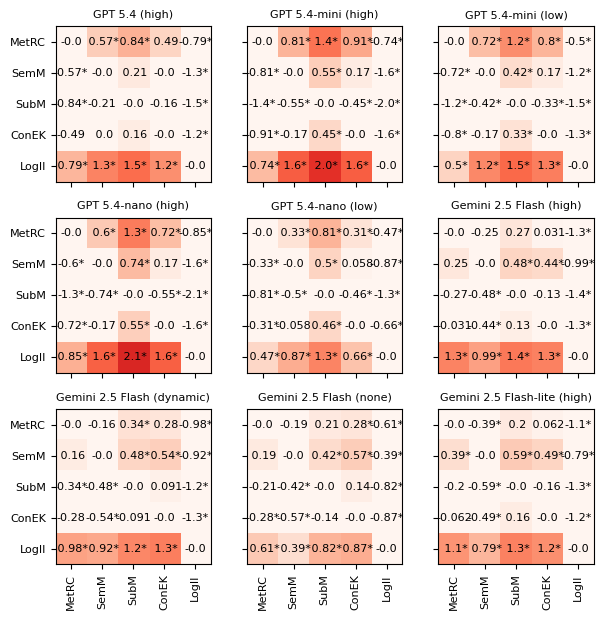

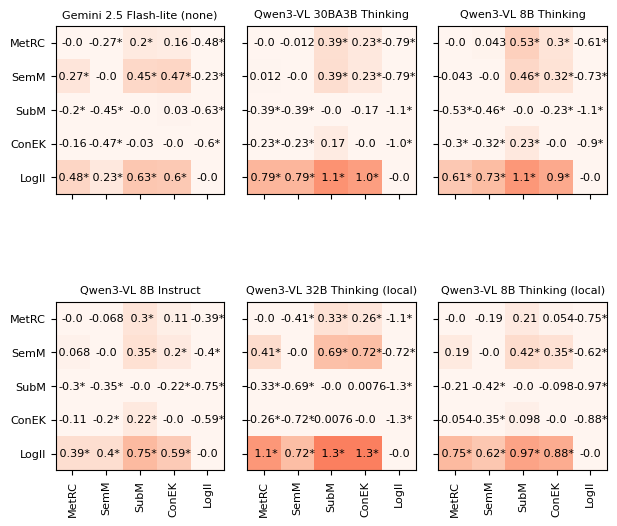

In [60]:
results_by_model = {}
NROWS = 3
NCOLS = 3
NMODELS = NROWS * NCOLS
NIMG = len(model_ids) // NMODELS 
if len(model_ids) % NMODELS != 0:
    NIMG = NIMG + 1

categories_list = list(scores_by_item.keys())
for img_n in range(NIMG):
    start = img_n * NMODELS
    end = start + NMODELS
    n_images = min(end, len(model_ids)) - start

    n_rows = n_images // NCOLS
    if n_images % NCOLS != 0:
        n_rows = n_rows + 1

    fig, axs = plt.subplots(n_rows, NCOLS, figsize=(6.3,6.3), sharex=True, sharey=True)
    for f, filter_id in enumerate(model_ids[start:end]):
        if NCOLS > 1 and n_rows > 1:
            ax = axs[f // NCOLS][f % NCOLS]
        else:
            ax = axs[f]
        #print(f'======================================================{filter_id}===============================================================')
        #convert to error_id -> paper_id -> score_array format
        results_by_item = {}
        for model_id, input_type, error_id, paper_id, score in results:
            if model_id != filter_id:
                continue

            if error_id not in results_by_item:
                results_by_item[error_id] = {}

            curr = results_by_item[error_id]

            if paper_id not in curr:
                curr[paper_id] = []

            curr_list = curr[paper_id]

            curr_list.append(score)

        #convert to error_id -> paper_id -> avg_score format
        scores_by_item = {}
        for error_id, res in results_by_item.items():
            weakness_scores = {}

            for paper_id, score_arr in res.items():
                avg_score = sum(score_arr) / len(score_arr)
                weakness_scores[paper_id] = avg_score

            scores_by_item[error_id] = weakness_scores

        cat_diffs, cat_comparisons_pvalues = category_comparison(scores_by_item)
        category_names = [error_cat_to_acronym[base64.urlsafe_b64decode(k).decode()] for k in categories_list]

        show_x = ((f % NCOLS) == 0)
        show_y = ((f//NCOLS) == NROWS-1)
        im = make_heatmap(ax, model_id_to_name[filter_id], cat_diffs, cat_comparisons_pvalues, category_names, category_names, show_x=show_x, show_y=show_y)
        #print_table_with_pvalues(cat_diffs, cat_comparisons_pvalues, category_names, [''] + category_names)

        #print(f'============================================================================================================================')

    #axs[-1][-1].remove()

    # fig.colorbar(
    #     im,
    #     ax=axs,
    #     label="Value",
    #     shrink=0.1,
    #     orientation='horizontal',
    #     location='bottom'
    # )

    #axs[-1][-1].remove()

    for _ in range((n_rows * NCOLS) - n_images):
        if NCOLS > 1 and n_rows > 1:
            axs[-1][-1].remove()
        else:
            axs[-1].remove()

    fig.tight_layout()
    plt.savefig(f'weakness_diffs_{img_n}.png', dpi=300, bbox_inches='tight')
    #fig.savefig(f'weakness_diffs_{img_n}.png', )

In [61]:
print_table_with_pvalues(cat_diffs, cat_comparisons_pvalues, category_names, [''] + category_names)

                                                       MetRC                 SemM                 SubM                ConEK                LogII 
MetRC                                                   -0.0               -0.191                0.209               0.0543               -0.753*
SemM                                                   0.191                 -0.0                0.415*               0.348*              -0.622*
SubM                                                  -0.209               -0.415*                -0.0              -0.0985               -0.967*
ConEK                                                -0.0543               -0.348*              0.0985                 -0.0               -0.881*
LogII                                                  0.753*               0.622*               0.967*               0.881*                -0.0 


In [62]:
a = [1,3,4,5,1,2,3]
b = [1,4,2,4,5,5,1,2]
print(stats.ttest_ind(a, b, equal_var=False))

print((sum(a)/len(a)) - (sum(b)/len(b)))

TtestResult(statistic=np.float64(-0.34727944810393946), pvalue=np.float64(0.7339417576274487), df=np.float64(12.993875095701625))
-0.2857142857142856


## Claim: Models perform the best on Logically Invalid Analysis

In [63]:
results_by_model = {}
FILTER_WEAKNESS = 'LogII'
print(f'======================================================{FILTER_WEAKNESS}===============================================================')
header_format = '{:>40} {:>20} {:>20} {:>20} {:>20} {:>20}'
row_format = '{:40} {:20.3}{:1} {:20.3}{:1} {:20.3}{:1} {:20.3}{:1} {:20.3}{:1}'

category_names = [error_cat_to_acronym[base64.urlsafe_b64decode(k).decode()] for k in list(scores_by_item.keys())]
print(header_format.format('', *category_names))

for filter_id in model_ids:
    results_by_item = {}
    for model_id, input_type, error_id, paper_id, score in results:
        if model_id != filter_id:
            continue

        if error_id not in results_by_item:
            results_by_item[error_id] = {}

        curr = results_by_item[error_id]

        if paper_id not in curr:
            curr[paper_id] = []

        curr_list = curr[paper_id]

        curr_list.append(score)

    scores_by_item = {}
    for error_id, res in results_by_item.items():
        weakness_scores = {}

        for paper_id, score_arr in res.items():
            avg_score = sum(score_arr) / len(score_arr)
            weakness_scores[paper_id] = avg_score

        scores_by_item[error_id] = weakness_scores

    cat_comparisons = np.zeros((len(scores_by_item.keys()),len(scores_by_item.keys())))
    cat_scores1 = np.zeros((len(scores_by_item.keys()),len(scores_by_item.keys())))
    cat_scores2 = np.zeros((len(scores_by_item.keys()),len(scores_by_item.keys())))

    for i, category1 in enumerate(scores_by_item.keys()):
        cat1_dict = scores_by_item[category1]
        for j, category2 in enumerate(scores_by_item.keys()):
            cat2_dict = scores_by_item[category2]

            common_keys = set(cat1_dict.keys()).intersection(set(cat2_dict.keys()))
            cat1_scores = [cat1_dict[k] for k in common_keys]
            cat2_scores = [cat2_dict[k] for k in common_keys]

            #print(stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue)
            cat_comparisons[i][j] = stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue
            cat_scores1[i][j] = sum(cat1_scores)/len(cat1_scores)
            cat_scores2[i][j] = sum(cat2_scores)/len(cat2_scores)

    #header_format = '{:>5} {:>20} {:>20} {:>20} {:>20} {:>20}'
    #row_format = '{:5} {:20.3} {:20.3} {:20.3} {:20.3} {:20.3}'

    category_names = [error_cat_to_acronym[base64.urlsafe_b64decode(k).decode()] for k in list(scores_by_item.keys())]
    #print(header_format.format('', *category_names))
    for i, k1 in enumerate(scores_by_item.keys()):
        cat = category_names[i]

        if cat != FILTER_WEAKNESS:
            continue


        cat_pvalues = cat_comparisons[i]

        #print(row_format.format(filter_id, *cat_pvalues))
        diffs = [a-b for a,b in zip(cat_scores1[i], cat_scores2[i])]
        #print(row_format.format(f'  {FILTER_WEAKNESS}', *cat_scores1[i]))
        #print(row_format.format(f'  other', *cat_scores2[i]))

        print_vals = []
        for i, diff in enumerate(diffs):
            print_vals.append(diff)
            sig = '*' if cat_pvalues[i] < 0.05 else ''
            print_vals.append(sig)

        print(row_format.format(filter_id, *print_vals))

print('================================================================================================================================================')

======================================================LogII===============================================================
                                                        MetRC                 SemM                 SubM                ConEK                LogII
gpt_54                                                  0.787*                 1.26*                 1.47*                 1.15*                  0.0 
gpt_54_mini                                              0.74*                  1.6*                  2.0*                 1.59*                  0.0 
gpt_54_mini_low                                           0.5*                 1.21*                 1.51*                  1.3*                  0.0 
gpt_54_nano                                             0.847*                 1.56*                 2.09*                 1.57*                  0.0 
gpt_54_nano_low                                         0.467*                0.872*                 1.25*                0.659